# Physics-Informed Trajectory Diffusion
### Conditional DDPM for Multi-Step 2D Trajectory Prediction

## 1. Contexte et problématique

La prédiction de trajectoires constitue une composante importante des **world models**, notamment pour anticiper l'évolution d'environnements dynamiques.

Les modèles physiques permettent de prédire cette évolution à partir de lois connues, mais leurs approximations peuvent devenir insuffisantes face à des dynamiques non linéaires, des perturbations ou des paramètres inconnus.

Les **Denoising Diffusion Probabilistic Models (DDPM)** offrent une approche d'apprentissage permettant de modéliser des trajectoires à partir de données. Leur combinaison avec des connaissances physiques pourrait permettre de corriger certaines erreurs d'un modèle physique simplifié.

Ce projet étudie cette hypothèse à travers la **prédiction de trajectoires futures 2D à partir d'observations initiales**, en comparant des approches physiques, déterministes et génératives.

**Objectif scientifique :** vérifier si un modèle corrige les prédictions d'une loi physique **incomplète** sur des trajectoires futures non observées, sans utiliser d'observations futures.

**Comparaisons :** (1) physique simplifiée, (2) MLP déterministe apprenant un résidu, (3) DDPM sans physique, (4) DDPM conditionné sur la physique et apprenant un résidu.

**Attention :** une amélioration n'est pas garantie. Un DDPM n'est pas nécessairement meilleur qu'un MLP. Il s'agit d'un modèle de diffusion **dans l'espace des trajectoires 2D**.

**Environnement :** Google Colab - Python, PyTorch, GPU T4 recommandé.


## 1. Dépendances, reproductibilité et configuration

In [1]:
import os, time, random, math, copy
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

SEED = 2026
TRAIN_N = 6000
TEST_N = 1000
OOD_N = 500
OBS = 4                 # premières observations disponibles
HORIZON = 10            # prochaines positions cachées / à prédire
N_STEPS = OBS + HORIZON
DT = 0.22
DIFF_STEPS = 40
TRAIN_STEPS = 1800       # chacune des trois architectures entraînées
BATCH_SIZE = 256
LR = 8e-4
SAMPLES_PER_CASE = 4   # moyenne de 4 tirages DDPM par trajectoire
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| torch:', torch.__version__)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(SEED)
# Facilite l'exécution CPU (évite la sur-souscription de threads)
if DEVICE=='cpu': torch.set_num_threads(min(4, os.cpu_count() or 1))

Device: cpu | torch: 2.14.1+cpu


## 2. Données synthétiques : dynamique réelle ≠ physique simplifiée

La trajectoire réelle suit un oscillateur amorti **non linéaire** avec force d'entraînement dépendante de la position. La baseline ignore ces termes et utilise un ressort-amortisseur fixe. Les **4 premières positions** sont observées ; les 10 suivantes sont masquées et servent de vérité terrain uniquement pendant l'entraînement et l'évaluation. Aucun modèle ne reçoit les futures positions comme entrée.

In [2]:
def simulate(n, seed, ood=False):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-0.8, 0.8, (n,2)).astype(np.float32)
    v = rng.uniform(-0.6, 0.6, (n,2)).astype(np.float32)
    if ood:
        k = rng.uniform(0.8, 1.35, (n,1)).astype(np.float32)
        gamma = rng.uniform(0.05, 0.25, (n,1)).astype(np.float32)
        nonlinear = rng.uniform(0.30,0.60,(n,1)).astype(np.float32)
        drive = rng.uniform(0.25,0.48,(n,1)).astype(np.float32)
    else:
        k = rng.uniform(0.55, 1.05, (n,1)).astype(np.float32)
        gamma = rng.uniform(0.08, 0.28, (n,1)).astype(np.float32)
        nonlinear = rng.uniform(0.10,0.40,(n,1)).astype(np.float32)
        drive = rng.uniform(0.10,0.30,(n,1)).astype(np.float32)
    out = [x.copy()]
    for t in range(1, N_STEPS):
        # Le simulateur réel est caché à la baseline.
        field = np.stack((np.sin(2.3*x[:,1]), np.sin(2.1*x[:,0])),axis=1)
        a = -k*x - gamma*v - nonlinear*x**3 + drive*field
        v = v + DT*a
        x = x + DT*v
        out.append(x.copy())
    return np.stack(out,axis=1).astype(np.float32)

def physics_baseline(obs):
    # Modèle intentionnellement imparfait, paramétré uniquement par les points observés
    k0, gamma0 = 0.72, 0.16
    x = obs[:,-1].copy()
    v = (obs[:,-1]-obs[:,-2])/DT
    pred=[]
    for _ in range(HORIZON):
        a=-k0*x-gamma0*v
        v=v+DT*a
        x=x+DT*v
        pred.append(x.copy())
    return np.stack(pred,axis=1).astype(np.float32)

train = simulate(TRAIN_N,SEED)
test = simulate(TEST_N,SEED+1)
ood = simulate(OOD_N,SEED+2,ood=True)
train_obs, test_obs, ood_obs = train[:,:OBS],test[:,:OBS],ood[:,:OBS]
train_y,test_y,ood_y = train[:,OBS:],test[:,OBS:],ood[:,OBS:]
train_p,test_p,ood_p = [physics_baseline(z) for z in (train_obs,test_obs,ood_obs)]
# Normalisation uniquement sur TRAIN pour éviter la fuite de données
obs_mu = train_obs.mean((0,1),keepdims=True); obs_sd = train_obs.std((0,1),keepdims=True)+1e-5
out_mu = train_y.mean((0,1),keepdims=True); out_sd = train_y.std((0,1),keepdims=True)+1e-5
resid_mu = (train_y-train_p).mean((0,1),keepdims=True)
resid_sd = (train_y-train_p).std((0,1),keepdims=True)+1e-5

def pack(obs,phys,y=None):
    c_obs = ((obs-obs_mu)/obs_sd).reshape(len(obs),-1)
    c_phys = ((phys-out_mu)/out_sd).reshape(len(phys),-1)
    c_full = np.concatenate([c_obs,c_phys],axis=1).astype(np.float32)
    c_nophys = c_obs.astype(np.float32)
    if y is None: return c_nophys,c_full
    target = ((y-out_mu)/out_sd).reshape(len(y),-1).astype(np.float32)
    residual = ((y-phys-resid_mu)/resid_sd).reshape(len(y),-1).astype(np.float32)
    return c_nophys,c_full,target,residual
tr_no,tr_full,tr_y,tr_r=pack(train_obs,train_p,train_y)
te_no,te_full=pack(test_obs,test_p)
oo_no,oo_full=pack(ood_obs,ood_p)
print('Data:',train.shape,test.shape,ood.shape,'| physics test error:',np.linalg.norm(test_p-test_y,axis=-1).mean().round(4))

Data: (6000, 14, 2) (1000, 14, 2) (500, 14, 2) | physics test error: 0.1178


## 3. Modèles : réseau déterministe et deux DDPM

In [3]:
D = HORIZON*2
class MLP(nn.Module):
    def __init__(self, ins, outs, hidden=192):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(ins,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,outs))
    def forward(self,x):return self.net(x)

class NoisePredictor(nn.Module):
    def __init__(self, ctx):
        super().__init__()
        self.net=MLP(D+ctx+32,D,256)
    def forward(self,xt,context,t):
        # Encodage temporel sinusoïdal
        freq=torch.exp(torch.arange(16,device=xt.device).float()*(-math.log(10000)/15))
        v=t.float().unsqueeze(1)*freq.unsqueeze(0)
        emb=torch.cat([torch.sin(v),torch.cos(v)],1)
        return self.net(torch.cat([xt,context,emb],1))

# Calendrier cosine : alpha_bar au dernier pas proche de zéro
s=0.008
idx=torch.arange(DIFF_STEPS+1,dtype=torch.float64)
a_bar=(torch.cos(((idx/DIFF_STEPS)+s)/(1+s)*math.pi/2)**2)
a_bar=(a_bar/a_bar[0]).clamp(min=1e-8)
betas=(1-a_bar[1:]/a_bar[:-1]).clamp(1e-5,0.999).float().to(DEVICE)
alphas=1-betas
alpha_cum=torch.cumprod(alphas,0)
print('Final alpha_bar:',alpha_cum[-1].item())

Final alpha_bar: 1.5171930272117606e-06


## 4. Entraînement : 3 architectures, même jeu de données

Training deterministic residual MLP...
Training DDPM without physical input...
Training physics-conditioned residual DDPM...
Training seconds: 49.6
MLP residual final loss: 0.1298
DDPM final loss: 0.0634
Physics + DDPM final loss: 0.0897


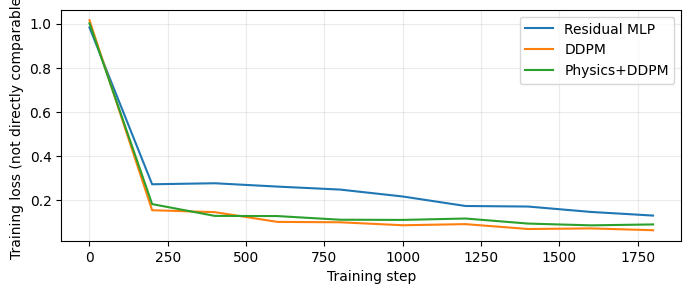

In [4]:
def train_mlp(context, target, steps=TRAIN_STEPS):
    model=MLP(context.shape[1],D).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR)
    c=torch.tensor(context,device=DEVICE)
    y=torch.tensor(target,device=DEVICE)
    history=[]; model.train()
    for step in range(steps):
        ix=torch.randint(len(c),(BATCH_SIZE,),device=DEVICE)
        loss=((model(c[ix])-y[ix])**2).mean()
        optimizer.zero_grad();loss.backward();optimizer.step()
        if step%200==0 or step==steps-1:
            history.append((step,float(loss.detach().cpu())))
    return model,history

def train_ddpm(context,target,steps=TRAIN_STEPS):
    model=NoisePredictor(context.shape[1]).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR)
    c=torch.tensor(context,device=DEVICE)
    y=torch.tensor(target,device=DEVICE)
    history=[]; model.train()
    for step in range(steps):
        ix=torch.randint(len(c),(BATCH_SIZE,),device=DEVICE)
        y0=y[ix]; batch_c=c[ix]
        t=torch.randint(0,DIFF_STEPS,(len(ix),),device=DEVICE)
        eps=torch.randn_like(y0)
        ab=alpha_cum[t,None]
        xt=ab.sqrt()*y0+(1-ab).sqrt()*eps
        pred=model(xt,batch_c,t)
        loss=((pred-eps)**2).mean()
        optimizer.zero_grad();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),2.0);optimizer.step()
        if step%200==0 or step==steps-1:
            history.append((step,float(loss.detach().cpu())))
    return model,history

start=time.time()
print('Training deterministic residual MLP...')
res_mlp,h_mlp=train_mlp(tr_full,tr_r)
print('Training DDPM without physical input...')
plain_ddpm,h_plain=train_ddpm(tr_no,tr_y)
print('Training physics-conditioned residual DDPM...')
hybrid_ddpm,h_hybrid=train_ddpm(tr_full,tr_r)
print('Training seconds:',round(time.time()-start,1))
for label,h in [('MLP residual',h_mlp),('DDPM',h_plain),('Physics + DDPM',h_hybrid)]:
    print(label, 'final loss:',round(h[-1][1],4))
plt.figure(figsize=(8,3))
for label,h in [('Residual MLP',h_mlp),('DDPM',h_plain),('Physics+DDPM',h_hybrid)]:
    plt.plot([a for a,b in h],[b for a,b in h],label=label)
plt.xlabel('Training step');plt.ylabel('Training loss (not directly comparable)');plt.legend();plt.grid(alpha=.25);plt.show()

## 5. Échantillonnage DDPM corrigé (posterior exact) et prédictions

Les DDPM reconstruisent les positions futures sans accès à la vérité terrain. Plusieurs tirages sont moyennés pour obtenir une estimation de position ; cette moyenne réduit l'aléa et doit être annoncée dans les résultats.

In [5]:
@torch.no_grad()
def sample_ddpm(model, context, draws=SAMPLES_PER_CASE, chunk=256, seed=125):
    model.eval()
    gen=torch.Generator(device=DEVICE).manual_seed(seed)
    outputs=[]
    for offset in range(0,len(context),chunk):
        ctx=torch.tensor(context[offset:offset+chunk],device=DEVICE)
        n=len(ctx)
        c=ctx.repeat_interleave(draws,dim=0)
        x=torch.randn((n*draws,D),device=DEVICE,generator=gen)
        for i in range(DIFF_STEPS-1,-1,-1):
            t=torch.full((len(x),),i,device=DEVICE,dtype=torch.long)
            eps=model(x,c,t)
            a=alphas[i];abar=alpha_cum[i]
            # Clipped x0 + posterior DDPM : numerically stable even at last cosine step
            x0=((x-torch.sqrt(1-abar)*eps)/torch.sqrt(abar)).clamp(-3.5,3.5)
            if i>0:
                prev=alpha_cum[i-1]
                coef_x0=betas[i]*torch.sqrt(prev)/(1-abar)
                coef_xt=(1-prev)*torch.sqrt(a)/(1-abar)
                var=(betas[i]*(1-prev)/(1-abar)).clamp(min=0)
                x=coef_x0*x0+coef_xt*x+torch.sqrt(var)*torch.randn(x.shape,device=DEVICE,generator=gen)
            else:
                x=x0
        outputs.append(x.view(n,draws,D).mean(1).cpu().numpy())
    return np.concatenate(outputs,axis=0).reshape(-1,HORIZON,2)

@torch.no_grad()
def predict_all(cno,cfull,physics,seed=125):
    res_mlp.eval()
    with torch.no_grad():
        r_pred=res_mlp(torch.tensor(cfull,device=DEVICE)).cpu().numpy().reshape(-1,HORIZON,2)
    pred_mlp=physics+ r_pred*resid_sd+resid_mu
    pred_plain=sample_ddpm(plain_ddpm,cno,seed=seed)*out_sd+out_mu
    pred_hybrid=physics+sample_ddpm(hybrid_ddpm,cfull,seed=seed+1)*resid_sd+resid_mu
    return {'Physics baseline':physics,'Residual MLP':pred_mlp,'DDPM only':pred_plain,'Physics + DDPM':pred_hybrid}

print('Predicting in-distribution test...')
results=predict_all(te_no,te_full,test_p,seed=SEED+9)
print('Predicting OOD test...')
results_ood=predict_all(oo_no,oo_full,ood_p,seed=SEED+10)

Predicting in-distribution test...
Predicting OOD test...


## 6. Évaluation : trajectoires inédites, OOD, intervalles de confiance appariés


TEST ID
Physics baseline    : ADE 0.1178 | médiane 0.1092
Residual MLP        : ADE 0.0415 | médiane 0.0368
DDPM only           : ADE 0.0824 | médiane 0.0721
Physics + DDPM      : ADE 0.0635 | médiane 0.0549

TEST OOD (dynamique déplacée)
Physics baseline    : ADE 0.1860 | médiane 0.1743
Residual MLP        : ADE 0.0886 | médiane 0.0799
DDPM only           : ADE 0.1294 | médiane 0.1223
Physics + DDPM      : ADE 0.1097 | médiane 0.1015

TEST ID – bootstrap apparié
Residual MLP        : gain absolu vs physique = +0.0763, IC95% [+0.0729, +0.0799]
DDPM only           : gain absolu vs physique = +0.0354, IC95% [+0.0316, +0.0392]
Physics + DDPM      : gain absolu vs physique = +0.0544, IC95% [+0.0507, +0.0579]

TEST OOD – bootstrap apparié
Residual MLP        : gain absolu vs physique = +0.0974, IC95% [+0.0926, +0.1020]
DDPM only           : gain absolu vs physique = +0.0567, IC95% [+0.0514, +0.0621]
Physics + DDPM      : gain absolu vs physique = +0.0763, IC95% [+0.0720, +0.0809]


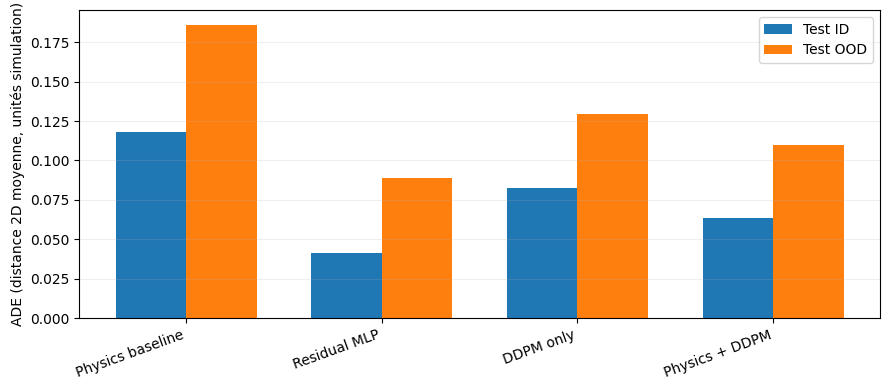

In [6]:
def score_table(predictions,truth):
    return {k:np.linalg.norm(v-truth,axis=-1).mean(axis=1) for k,v in predictions.items()}

def report(predictions,truth,title):
    errors=score_table(predictions,truth)
    print('\n'+title)
    for k,e in errors.items():print(f'{k:20s}: ADE {e.mean():.4f} | médiane {np.median(e):.4f}')
    return errors

e_id=report(results,test_y,'TEST ID')
e_ood=report(results_ood,ood_y,'TEST OOD (dynamique déplacée)')

def paired_ci(errors,reference='Physics baseline',n_boot=2000,seed=7):
    rng=np.random.default_rng(seed)
    base=errors[reference]
    for label in errors:
        if label==reference:continue
        delta=base-errors[label]   # positif = méthode meilleure que baseline
        ids=rng.integers(0,len(delta),size=(n_boot,len(delta)))
        means=delta[ids].mean(axis=1)
        lo,hi=np.percentile(means,[2.5,97.5])
        print(f'{label:20s}: gain absolu vs physique = {delta.mean():+.4f}, IC95% [{lo:+.4f}, {hi:+.4f}]')

print('\nTEST ID – bootstrap apparié')
paired_ci(e_id)
print('\nTEST OOD – bootstrap apparié')
paired_ci(e_ood)

fig,ax=plt.subplots(figsize=(9,4))
names=list(e_id)
xx=np.arange(len(names));w=.36
ax.bar(xx-w/2,[e_id[k].mean() for k in names],width=w,label='Test ID')
ax.bar(xx+w/2,[e_ood[k].mean() for k in names],width=w,label='Test OOD')
ax.set_xticks(xx);ax.set_xticklabels(names,rotation=20,ha='right')
ax.set_ylabel('ADE (distance 2D moyenne, unités simulation)');ax.legend();ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()

## 7. Visualisation d’exemples cachés

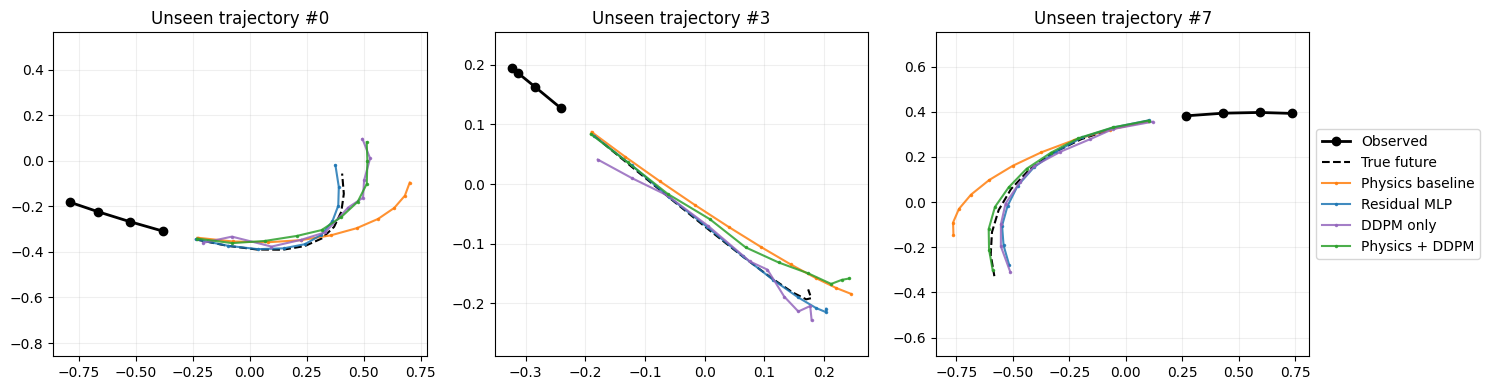

In [7]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,j in zip(axes,[0,3,7]):
    ax.plot(test_obs[j,:,0],test_obs[j,:,1],'ko-',label='Observed',lw=2)
    ax.plot(test_y[j,:,0],test_y[j,:,1],'k--',label='True future')
    for name,color in [('Physics baseline','tab:orange'),('Residual MLP','tab:blue'),('DDPM only','tab:purple'),('Physics + DDPM','tab:green')]:
        xy=results[name][j]
        ax.plot(xy[:,0],xy[:,1],marker='.',markersize=3,label=name,color=color,alpha=.85)
    ax.set_title(f'Unseen trajectory #{j}');ax.axis('equal');ax.grid(alpha=.2)
axes[-1].legend(loc='center left',bbox_to_anchor=(1,0.5))
plt.tight_layout();plt.show()


## 8. Conclusions et formulation scientifique

### 8.1. Synthèse des résultats

Cette étude compare quatre approches de prédiction de trajectoires 2D : un modèle physique simplifié, un MLP résiduel, un DDPM standard et un DDPM conditionné par la physique.

Les modèles ont été évalués sur des trajectoires synthétiques, dans des conditions standards (*In-Distribution*, ID) et sous changement de distribution (*Out-of-Distribution*, OOD).

| Méthode | ADE (ID) ↓ | ADE (OOD) ↓ |
|---|---:|---:|
| Physique seule | 0,1178 | 0,1860 |
| MLP résiduel | **0,0415** | **0,0886** |
| DDPM seul | 0,0824 | 0,1294 |
| DDPM + physique | 0,0635 | 0,1097 |

*ADE (Average Displacement Error) : erreur moyenne de position sur les trajectoires prédites. Une valeur plus faible indique une meilleure précision.*

### 8.2. Principaux résultats

**1. Apport du DDPM conditionné par la physique**

Le DDPM hybride réduit l'erreur de prédiction de :

- **46,1 % en ID** par rapport au modèle physique seul.
- **41,0 % en OOD** par rapport au modèle physique seul.

Les intervalles de confiance bootstrap à 95 % des réductions absolues d'erreur sont :

- ID : **[0,0507 ; 0,0579]**
- OOD : **[0,0720 ; 0,0809]**

Ces résultats soutiennent l'existence d'un gain sur les trajectoires évaluées pour cette exécution.

**2. Comparaison avec l'apprentissage déterministe**

Le **MLP résiduel obtient les meilleures performances** en ID (0,0415) et en OOD (0,0886).

La diffusion ne démontre donc pas de supériorité par rapport à l'apprentissage déterministe des résidus physiques.

**3. Apport du conditionnement physique**

Le DDPM hybride réduit l'erreur de **22,9 % en ID** et de **15,2 % en OOD** par rapport au DDPM sans physique.

Toutefois, ces modèles ne disposent pas exactement des mêmes informations de conditionnement. Les gains observés ne peuvent donc pas être attribués exclusivement à l'architecture générative.

**4. Généralisation hors distribution**

Les quatre approches présentent une augmentation de l'erreur en OOD.

Le DDPM hybride conserve néanmoins une meilleure précision que la baseline physique simplifiée, suggérant une capacité à corriger certaines erreurs dues à une modélisation physique incomplète dans les conditions testées.

### 8.3. Limites scientifiques

- **Données synthétiques :** les expériences portent sur des trajectoires 2D simulées.
- **Physique simplifiée :** le modèle physique utilisé est une approximation volontairement incomplète de la dynamique simulée.
- **Prédiction de positions :** le DDPM prédit des trajectoires numériques, sans génération directe d'images.
- **Persistance visuelle :** l'identité des objets et leur réapparition après occultation ne sont pas explicitement évaluées..
- **Reproductibilité :** un seul entraînement par architecture a été évalué. Les intervalles bootstrap ne mesurent pas la variabilité entre entraînements indépendants.
- **Valeur spécifique de la diffusion :** les résultats ne démontrent pas de supériorité sur le MLP résiduel.

### 8.4. Conclusion scientifique

Les résultats montrent qu'un **DDPM conditionné par une approximation physique permet de réduire l'erreur de prédiction de trajectoires futures**, y compris sous changement de distribution, lorsque le modèle physique disponible ne décrit qu'imparfaitement la dynamique simulée.

L'approche hybride obtient une **réduction d'erreur de 46,1 % en ID et de 41,0 % en OOD** par rapport à la baseline physique simplifiée.

Cependant, le **MLP résiduel reste plus performant**, ce qui suggère que le bénéfice principal observé provient de l'apprentissage des corrections à la physique simplifiée, plutôt que d'un avantage intrinsèque de la diffusion.

Cette étude met ainsi en évidence l'intérêt de combiner **modélisation physique et apprentissage automatique**, tout en soulignant l'importance de comparer les approches génératives à des baselines déterministes.

### 8.5. Perspectives

Pour prolonger cette étude vers les **world models**, plusieurs extensions seraient pertinentes :

1. **Prédiction multimodale :** modéliser plusieurs trajectoires futures plausibles sous incertitude.
2. **Persistance visuelle :** intégrer des observations sous forme d'images et évaluer la conservation de l'identité des objets après occultation.
3. **Cohérence physique :** étudier l'intégration de contraintes physiques directement pendant l'apprentissage ou la génération.
4. **Validation robotique :** évaluer l'utilité des prédictions pour la planification et le contrôle.

